# Xử lý 9 chuỗi hàng hóa từ Investing.com (Daily, 2016–2026)

Notebook đọc các CSV trong thư mục `new data`, chuẩn hóa cột `Date` và `Price`, kiểm tra độ phủ, ghép theo lịch giao dịch của Copper, tính Pearson/Spearman trên **mức giá** và **lợi suất ngày**, rồi xuất dataset hoàn chỉnh.

Để tránh dùng thông tin tương lai, dữ liệu thiếu chỉ được **forward-fill tối đa 3 ngày giao dịch Copper**; không backward-fill.

In [1]:
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

START_DATE = pd.Timestamp('2016-01-01')
END_DATE = pd.Timestamp('2026-12-31')
MAX_FFILL = 3

DATA_DIR = Path('new data')
if not DATA_DIR.exists():
    DATA_DIR = Path('lstm') / 'new data'
if not DATA_DIR.exists():
    raise FileNotFoundError('Không tìm thấy thư mục new data. Hãy chạy notebook từ thư mục lstm hoặc thư mục gốc dự án.')

OUTPUT_DATASET = DATA_DIR / '13-11-2026_dataset_9_commodities_daily.csv'
OUTPUT_CORR = DATA_DIR / '13-11-2026_correlation_summary.csv'
OUTPUT_COVERAGE = DATA_DIR / '13-11-2026_data_coverage.csv'
print('Data folder:', DATA_DIR.resolve())

Data folder: D:\University\ptdlkd\lstm\new data


In [2]:
# Nhận diện theo token trong tên file; hỗ trợ cả tên mặc định của Investing.com.
ASSET_PATTERNS = {
    'Copper': [('copper',)],
    'Aluminium': [('aluminium',), ('aluminum',)],
    'Nickel': [('nickel',)],
    'Tin': [('tin',)],
    'Iron_Ore_62': [('iron', 'ore'), ('tio',)],
    'Silver': [('silver',)],
    'Gold': [('gold',)],
    'WTI': [('wti',), ('crude', 'oil')],
    'Brent': [('brent',)],
}

def ascii_tokens(text):
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode().lower()
    return set(re.findall(r'[a-z0-9]+', text))

csv_files = sorted(DATA_DIR.glob('*.csv'))
output_names = {OUTPUT_DATASET.name, OUTPUT_CORR.name, OUTPUT_COVERAGE.name}
csv_files = [p for p in csv_files if p.name not in output_names]

file_map = {}
used = set()
for asset, alternatives in ASSET_PATTERNS.items():
    candidates = []
    for path in csv_files:
        tokens = ascii_tokens(path.stem)
        if any(set(pattern).issubset(tokens) for pattern in alternatives):
            candidates.append(path)
    candidates = [p for p in candidates if p not in used]
    if candidates:
        file_map[asset] = candidates[0]
        used.add(candidates[0])

missing = [asset for asset in ASSET_PATTERNS if asset not in file_map]
print(pd.DataFrame({'Asset': list(file_map), 'File': [file_map[x].name for x in file_map]}).to_string(index=False))
if missing:
    raise FileNotFoundError(f'Thiếu CSV cho: {missing}. Xem hướng dẫn tên file trong new data/README.md')

      Asset               File
     Copper      01_copper.csv
  Aluminium   02_aluminium.csv
     Nickel      03_nickel.csv
        Tin         04_tin.csv
Iron_Ore_62 05_iron_ore_62.csv
     Silver      06_silver.csv
       Gold        07_gold.csv
        WTI         08_wti.csv
      Brent       09_brent.csv


In [3]:
def read_csv_flexible(path):
    errors = []
    for encoding in ('utf-8-sig', 'utf-8', 'utf-16', 'latin1'):
        try:
            return pd.read_csv(path, sep=None, engine='python', encoding=encoding)
        except Exception as exc:
            errors.append(f'{encoding}: {exc}')
    raise ValueError(f'Không đọc được {path.name}: ' + ' | '.join(errors))

def normalize_col(text):
    return unicodedata.normalize('NFKD', str(text)).encode('ascii', 'ignore').decode().strip().lower()

def parse_price(series):
    cleaned = (series.astype(str).str.strip()
               .str.replace('−', '-', regex=False)
               .str.replace(r'[^0-9.\-]', '', regex=True))
    return pd.to_numeric(cleaned, errors='coerce')

def load_price_series(path, asset):
    raw = read_csv_flexible(path)
    columns = {normalize_col(c): c for c in raw.columns}
    date_col = next((columns[x] for x in ('date', 'ngay') if x in columns), None)
    price_col = next((columns[x] for x in ('price', 'close', 'last', 'gia') if x in columns), None)
    if date_col is None or price_col is None:
        raise ValueError(f'{path.name}: cần cột Date và Price/Close; hiện có {list(raw.columns)}')

    dates = pd.to_datetime(raw[date_col], errors='coerce', dayfirst=False)
    # Thử lại day-first cho những dòng chưa parse được.
    bad = dates.isna()
    if bad.any():
        dates.loc[bad] = pd.to_datetime(raw.loc[bad, date_col], errors='coerce', dayfirst=True)

    out = pd.DataFrame({'Date': dates, asset: parse_price(raw[price_col])})
    out = out.dropna().drop_duplicates('Date', keep='last')
    out = out[(out['Date'] >= START_DATE) & (out['Date'] <= END_DATE)]
    return out.sort_values('Date').set_index('Date')[asset]

series = {asset: load_price_series(path, asset) for asset, path in file_map.items()}
print('Đã đọc:', ', '.join(series))

Đã đọc: Copper, Aluminium, Nickel, Tin, Iron_Ore_62, Silver, Gold, WTI, Brent


In [4]:
coverage = []
for asset, s in series.items():
    coverage.append({
        'asset': asset,
        'file': file_map[asset].name,
        'first_date': s.index.min().date(),
        'last_date': s.index.max().date(),
        'valid_rows': int(s.notna().sum()),
        'duplicate_dates_after_cleaning': int(s.index.duplicated().sum()),
    })
coverage = pd.DataFrame(coverage)
coverage.to_csv(OUTPUT_COVERAGE, index=False, encoding='utf-8-sig')
display(coverage)

,asset,file,first_date,last_date,valid_rows,duplicate_dates_after_cleaning
0,Copper,01_copper.csv,2016-01-04,2026-11-13,2801,0
1,Aluminium,02_aluminium.csv,2016-01-04,2026-11-13,2748,0
2,Nickel,03_nickel.csv,2016-01-04,2026-11-13,2654,0
3,Tin,04_tin.csv,2016-01-04,2026-11-12,2736,0
4,Iron_Ore_62,05_iron_ore_62.csv,2016-01-04,2026-11-12,2734,0
5,Silver,06_silver.csv,2016-01-13,2026-11-13,2379,0
6,Gold,07_gold.csv,2016-01-04,2026-11-13,2412,0
7,WTI,08_wti.csv,2016-01-04,2026-11-13,2814,0
8,Brent,09_brent.csv,2016-01-13,2026-11-13,2800,0


In [5]:
# Copper là biến mục tiêu và lịch tham chiếu. Chỉ dùng thông tin đã xuất hiện trước đó.
base_index = series['Copper'].index
aligned = pd.DataFrame(index=base_index)
for asset, s in series.items():
    if asset == 'Copper':
        aligned[asset] = s.reindex(base_index)
    else:
        aligned[asset] = s.reindex(base_index).ffill(limit=MAX_FFILL)

missing_before_drop = aligned.isna().sum().rename('missing_after_ffill').to_frame()
dataset = aligned.dropna().reset_index().rename(columns={'index': 'Date'})
dataset.to_csv(OUTPUT_DATASET, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')

print(f'Aligned rows trước dropna: {len(aligned):,}')
print(f'Dataset hoàn chỉnh: {len(dataset):,} dòng; {dataset.Date.min().date()} -> {dataset.Date.max().date()}')
print('Output:', OUTPUT_DATASET.resolve())
display(missing_before_drop.T)
display(dataset.head())

Aligned rows trước dropna: 2,801
Dataset hoàn chỉnh: 2,710 dòng; 2016-01-13 -> 2026-11-13
Output: D:\University\ptdlkd\lstm\new data\13-11-2026_dataset_9_commodities_daily.csv


,Copper,Aluminium,Nickel,Tin,Iron_Ore_62,Silver,Gold,WTI,Brent
missing_after_ffill,0,0,83,1,0,7,0,0,7


,Date,Copper,Aluminium,Nickel,Tin,Iron_Ore_62,Silver,Gold,WTI,Brent
0,2016-01-13,1.9560,1462.5,8250.0,13305.0,40.42,14.156,1087.1,30.48,30.31
1,2016-01-14,1.9760,1483.0,8610.0,13260.0,40.59,13.748,1073.6,31.20,31.03
2,2016-01-15,1.9435,1473.0,8400.0,13205.0,40.79,13.896,1090.7,29.42,28.94
3,2016-01-19,1.9775,1481.0,8575.0,13225.0,41.32,14.121,1090.7,28.46,28.76
4,2016-01-20,1.9595,1469.0,8540.0,13390.0,41.19,14.160,1106.2,26.55,27.88


In [6]:
prices = dataset.set_index('Date')
returns = prices.pct_change(fill_method=None).dropna()

rows = []
for variable in [c for c in prices.columns if c != 'Copper']:
    rows.append({
        'variable': variable,
        'n_price': int(prices[['Copper', variable]].dropna().shape[0]),
        'pearson_price': prices['Copper'].corr(prices[variable], method='pearson'),
        'spearman_price': prices['Copper'].corr(prices[variable], method='spearman'),
        'n_return': int(returns[['Copper', variable]].dropna().shape[0]),
        'pearson_daily_return': returns['Copper'].corr(returns[variable], method='pearson'),
        'spearman_daily_return': returns['Copper'].corr(returns[variable], method='spearman'),
    })

corr_summary = pd.DataFrame(rows).sort_values('spearman_daily_return', key=lambda s: s.abs(), ascending=False)
corr_summary.to_csv(OUTPUT_CORR, index=False, encoding='utf-8-sig')
display(corr_summary.style.format(precision=4))
print('Correlation output:', OUTPUT_CORR.resolve())

,variable,n_price,pearson_price,spearman_price,n_return,pearson_daily_return,spearman_daily_return
1,Nickel,2710,0.4737,0.6907,2709,0.2942,0.5043
0,Aluminium,2710,0.9296,0.9467,2709,0.4599,0.4713
2,Tin,2710,0.9473,0.9287,2709,0.4110,0.4264
4,Silver,2710,0.8476,0.8549,2709,0.3424,0.3589
5,Gold,2710,0.8839,0.8524,2709,0.2430,0.2191
6,WTI,2710,0.6564,0.7092,2709,0.1930,0.2085
7,Brent,2710,0.6298,0.6678,2709,0.1950,0.2027
3,Iron_Ore_62,2710,0.4440,0.6110,2709,0.1434,0.1724


Correlation output: D:\University\ptdlkd\lstm\new data\13-11-2026_correlation_summary.csv


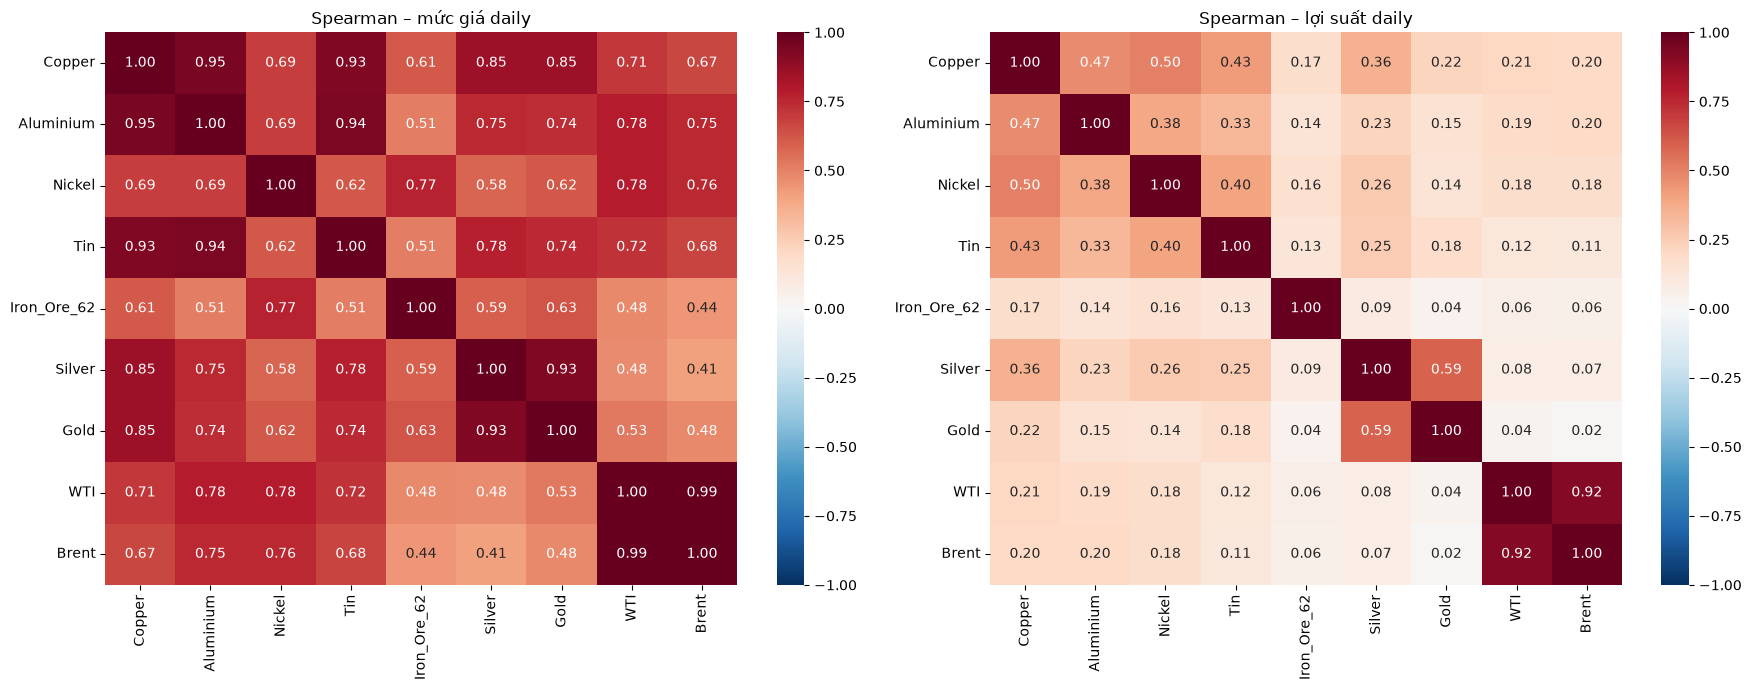

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(prices.corr(method='spearman'), cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=axes[0])
axes[0].set_title('Spearman – mức giá daily')
sns.heatmap(returns.corr(method='spearman'), cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', ax=axes[1])
axes[1].set_title('Spearman – lợi suất daily')
plt.tight_layout()
plt.show()

## Cách đọc kết quả

- `spearman_price`: đồng biến dài hạn của mức giá; có thể cao do cùng xu hướng/lạm phát.
- `spearman_daily_return`: quan hệ đồng biến trong biến động ngày; phù hợp hơn để sàng lọc tín hiệu dự báo ngắn hạn.
- Chỉ chọn biến cho mô hình sau khi xem cả độ phủ dữ liệu, độ ổn định theo thời gian và kiểm tra lag; không chọn chỉ vì tương quan mức giá cao.